# Who Sets Your Five Year Mortgage Rate? The Bank of Canada, the Bond Market, or the Banks

**Author:** John Khan

**Question.** When people talk about mortgage rates in Canada they usually talk about the Bank of Canada. But a five year fixed mortgage is priced for five years, so it should track the five year Government of Canada bond more closely than the overnight policy rate. This notebook checks that with the Bank of Canada's own data, and measures how far the posted rate and the rate people actually get sit above the bond yield.

**Data (all live from the Bank of Canada Valet API, https://www.bankofcanada.ca/valet/docs):**

| Series ID | What it is | Frequency |
|---|---|---|
| `V39079` | Target for the overnight rate (policy rate) | Business daily |
| `BD.CDN.5YR.DQ.YLD` | Government of Canada 5 year benchmark bond yield | Business daily |
| `V80691335` | Conventional mortgage, 5 year (the posted rate at chartered banks) | Weekly |
| `V122667786` | Interest rate on new uninsured residential mortgages, fixed 5 years and over, chartered banks | Monthly |

The window starts in April 2009, the first date the policy rate series has. If the API is down, the notebook reads the CSV snapshot it saved on the last good run (folder `data/`). On Kaggle, keep Internet on, or upload those CSVs as a dataset.

In [1]:
import io, os, json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BLUE = "#011F5B"
RED = "#990000"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})
TITLE_FONT = {"family": "serif", "weight": "bold", "size": 15}

VALET = "https://www.bankofcanada.ca/valet/observations/{ids}/json"
SNAPSHOT_DIR = "data"

def valet(series, start=None, snapshot=None):
    """Pull one or more Bank of Canada Valet series into a DataFrame.
    If the live pull fails, fall back to a CSV snapshot saved next to the notebook
    (on Kaggle, upload the snapshot CSV as a dataset and point SNAPSHOT_DIR at it)."""
    ids = ",".join(series)
    params = {"start_date": start} if start else {}
    try:
        r = requests.get(VALET.format(ids=ids), params=params, timeout=60)
        r.raise_for_status()
        obs = r.json()["observations"]
        rows = []
        for o in obs:
            row = {"date": o["d"]}
            for s in series:
                v = o.get(s, {}).get("v")
                row[s] = float(v) if v not in (None, "") else np.nan
            rows.append(row)
        df = pd.DataFrame(rows)
        df["date"] = pd.to_datetime(df["date"])
        df = df.set_index("date").sort_index()
        if snapshot:
            os.makedirs(SNAPSHOT_DIR, exist_ok=True)
            df.to_csv(os.path.join(SNAPSHOT_DIR, snapshot))
        print(f"Live pull OK: {ids} ({len(df)} rows, {df.index.min().date()} to {df.index.max().date()})")
        return df
    except Exception as e:
        path = os.path.join(SNAPSHOT_DIR, snapshot or "missing.csv")
        print(f"Live pull failed ({e}). Reading snapshot {path}")
        return pd.read_csv(path, index_col="date", parse_dates=True)

def style(ax, title, ylabel=None):
    ax.set_title(title, fontdict=TITLE_FONT, loc="left", color=BLUE)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax

def save(fig, name):
    os.makedirs("charts", exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join("charts", name), dpi=150, bbox_inches="tight")
    plt.show()


## 1. Pull the data

In [2]:
daily = valet(["V39079", "BD.CDN.5YR.DQ.YLD"], start="2009-04-01", snapshot="daily_policy_bond.csv")
posted = valet(["V80691335"], start="2009-04-01", snapshot="weekly_posted_5yr.csv")
effective = valet(["V122667786"], snapshot="monthly_effective_5yr_uninsured.csv")

daily = daily.rename(columns={"V39079": "policy", "BD.CDN.5YR.DQ.YLD": "bond5"})
posted = posted.rename(columns={"V80691335": "posted5"})
effective = effective.rename(columns={"V122667786": "effective5"})

# Monthly table: average of each month for the daily and weekly series.
# The effective rate series is dated on the first of the month.
m = pd.concat([
    daily.resample("MS").mean(),
    posted.resample("MS").mean(),
    effective.resample("MS").mean(),
], axis=1)
m = m[m.index >= "2009-05-01"]
m.tail()

Live pull OK: V39079,BD.CDN.5YR.DQ.YLD (4564 rows, 2009-04-01 to 2026-10-15)


Live pull OK: V80691335 (916 rows, 2009-04-01 to 2026-10-14)
Live pull OK: V122667786 (163 rows, 2013-01-01 to 2026-07-01)


,policy,bond5,posted5,effective5
date,,,,
2026-06-01,2.25,3.064545,6.09,4.35
2026-07-01,2.25,3.163182,6.09,4.49
2026-08-01,2.25,3.281500,6.09,NaN
2026-09-01,2.25,3.568000,6.09,NaN
2026-10-01,2.25,3.581000,6.19,NaN


## 2. The four rates side by side

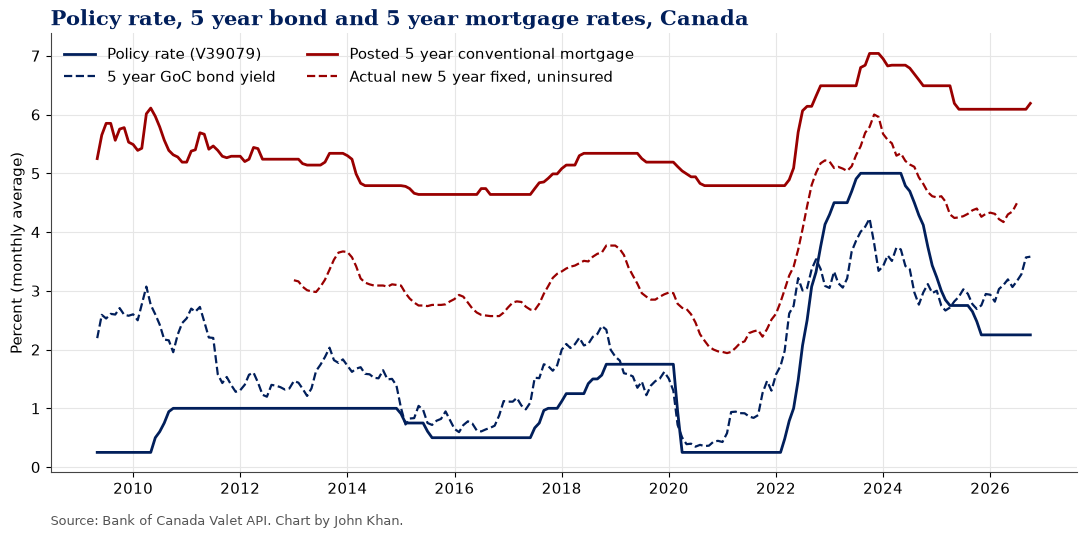

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(m.index, m["policy"], color=BLUE, lw=2, label="Policy rate (V39079)")
ax.plot(m.index, m["bond5"], color=BLUE, lw=1.6, ls="--", label="5 year GoC bond yield")
ax.plot(m.index, m["posted5"], color=RED, lw=2, label="Posted 5 year conventional mortgage")
ax.plot(m.index, m["effective5"], color=RED, lw=1.6, ls="--", label="Actual new 5 year fixed, uninsured")
style(ax, "Policy rate, 5 year bond and 5 year mortgage rates, Canada", "Percent (monthly average)")
ax.legend(loc="upper left", ncol=2)
ax.text(0, -0.12, "Source: Bank of Canada Valet API. Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "01_four_rates.png")

## 3. Which rate does the mortgage rate follow?

Levels can move together just because everything trended the same way. A stricter test is month to month changes. One detail matters here: the actual rate series is the rate on loans funded that month, and many of those loans had their rate locked weeks earlier. So I also let the bond yield lead by one and two months.

In [4]:
chg = m.diff()
lag_rows = []
for k in range(0, 4):
    lag_rows.append({
        "bond change k months earlier": k,
        "corr with posted change": round(chg["posted5"].corr(chg["bond5"].shift(k)), 2),
        "corr with actual change": round(chg["effective5"].corr(chg["bond5"].shift(k)), 2),
    })
lag_rows.append({"bond change k months earlier": "policy, same month",
                 "corr with posted change": round(chg["posted5"].corr(chg["policy"]), 2),
                 "corr with actual change": round(chg["effective5"].corr(chg["policy"]), 2)})
pd.DataFrame(lag_rows)

,bond change k months earlier,corr with posted change,corr with actual change
0,0,0.30,0.20
1,1,0.39,0.48
2,2,0.36,0.51
3,3,0.24,0.46
4,"policy, same month",0.28,0.56


In [5]:
# How much of the month to month movement does each driver explain? Simple least squares, R squared.
X_all = pd.DataFrame({
    "bond_t": chg["bond5"], "bond_t1": chg["bond5"].shift(1), "bond_t2": chg["bond5"].shift(2),
    "policy_t": chg["policy"], "policy_t1": chg["policy"].shift(1),
})
def r2(y, cols):
    df = pd.concat([chg[y], X_all[cols]], axis=1).dropna()
    A = np.column_stack([np.ones(len(df)), df[cols].values])
    coef, *_ = np.linalg.lstsq(A, df[y].values, rcond=None)
    resid = df[y].values - A @ coef
    return round(1 - (resid ** 2).sum() / ((df[y] - df[y].mean()) ** 2).sum(), 2), len(df)
models = {"bond only (this month and 2 prior)": ["bond_t", "bond_t1", "bond_t2"],
          "policy only (this month and 1 prior)": ["policy_t", "policy_t1"],
          "both": ["bond_t", "bond_t1", "bond_t2", "policy_t", "policy_t1"]}
r2_table = pd.DataFrame([{"model": k, "R2 posted": r2("posted5", v)[0], "R2 actual": r2("effective5", v)[0],
                          "months (actual)": r2("effective5", v)[1]} for k, v in models.items()])
r2_table

,model,R2 posted,R2 actual,months (actual)
0,bond only (this month and 2 prior),0.25,0.39,162
1,policy only (this month and 1 prior),0.09,0.33,162
2,both,0.26,0.50,162


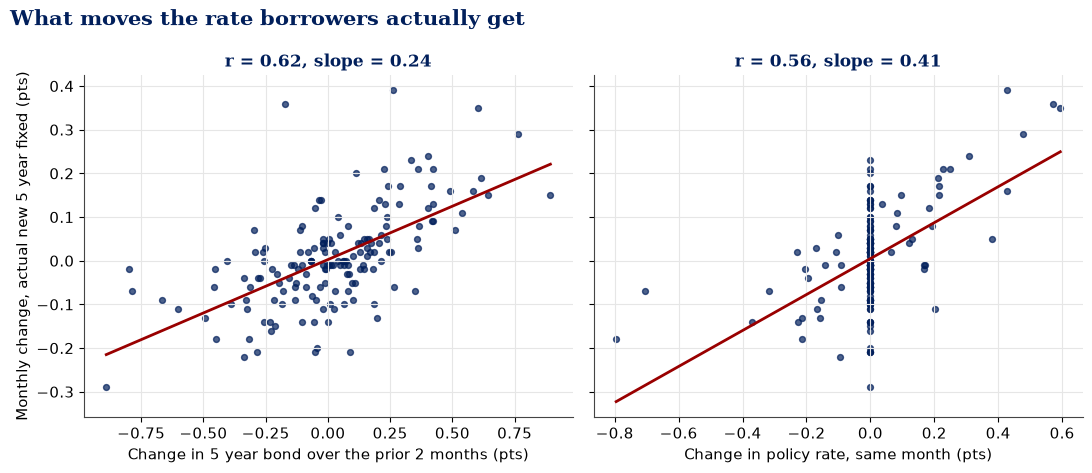

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
sc = pd.DataFrame({"actual": chg["effective5"],
                   "bond_prior2": chg["bond5"].shift(1) + chg["bond5"].shift(2),
                   "policy": chg["policy"]}).dropna()
for ax, x, lab in [(axes[0], "bond_prior2", "Change in 5 year bond over the prior 2 months"),
                   (axes[1], "policy", "Change in policy rate, same month")]:
    ax.scatter(sc[x], sc["actual"], s=18, color=BLUE, alpha=0.7)
    b = np.polyfit(sc[x], sc["actual"], 1)
    xs = np.linspace(sc[x].min(), sc[x].max(), 50)
    ax.plot(xs, b[0] * xs + b[1], color=RED, lw=2)
    ax.set_xlabel(lab + " (pts)")
    ax.set_title(f"r = {sc[x].corr(sc['actual']):.2f}, slope = {b[0]:.2f}", fontdict={"family": "serif", "size": 12}, color=BLUE)
axes[0].set_ylabel("Monthly change, actual new 5 year fixed (pts)")
fig.suptitle("What moves the rate borrowers actually get", fontfamily="serif", fontweight="bold", fontsize=15, color=BLUE, x=0.01, ha="left")
save(fig, "02_changes_scatter.png")

### A live example: the policy rate has not moved, mortgage rates have

The cell below finds the last policy rate change in the data and measures how the bond and mortgage rates moved after it.

In [7]:
pol = daily["policy"].dropna()
last_change = pol[pol.diff() != 0].index[-1]
start_month = (last_change + pd.offsets.MonthBegin(1)).normalize()
print(f"Last policy rate change: {last_change.date()} to {pol.loc[last_change]:.2f}%")
print(f"Policy rate on {pol.index[-1].date()}: {pol.iloc[-1]:.2f}%")
b = m["bond5"]
print(f"5 year bond, monthly average: low since then {b[b.index >= start_month].min():.2f}% ({b[b.index >= start_month].idxmin().strftime('%B %Y')}), latest {b.iloc[-1]:.2f}% ({b.index[-1].strftime('%B %Y')})")
pp = posted["posted5"].dropna(); pp = pp[pp.index >= last_change]
print(f"Posted 5 year: {pp.iloc[0]:.2f}% on {pp.index[0].date()}, {pp.iloc[-1]:.2f}% on {pp.index[-1].date()}")
ee = m["effective5"].dropna(); ee = ee[ee.index >= start_month]
print(f"Actual new 5 year fixed: low {ee.min():.2f}% ({ee.idxmin().strftime('%B %Y')}), latest {ee.iloc[-1]:.2f}% ({ee.index[-1].strftime('%B %Y')})")

Last policy rate change: 2025-10-30 to 2.25%
Policy rate on 2026-10-15: 2.25%
5 year bond, monthly average: low since then 2.75% (November 2025), latest 3.58% (October 2026)
Posted 5 year: 6.09% on 2025-11-05, 6.19% on 2026-10-14
Actual new 5 year fixed: low 4.17% (April 2026), latest 4.49% (July 2026)


## 4. How wide is the gap above the bond?

The spread over the five year bond is roughly what the bank keeps for funding, risk, and profit. The posted rate is a list price. Most borrowers get a discount, so the actual rate on new loans is the better measure of what people pay.

In [8]:
m["posted_spread"] = m["posted5"] - m["bond5"]
m["effective_spread"] = m["effective5"] - m["bond5"]
m["posted_minus_effective"] = m["posted5"] - m["effective5"]
summary = m[["posted_spread", "effective_spread", "posted_minus_effective"]].describe().round(2)
summary

,posted_spread,effective_spread,posted_minus_effective
count,210.00,163.00,163.00
mean,3.47,1.62,1.89
std,0.46,0.35,0.38
min,2.28,0.48,1.04
25%,3.14,1.39,1.68
50%,3.43,1.60,1.84
75%,3.83,1.87,2.08
max,4.60,2.62,2.85


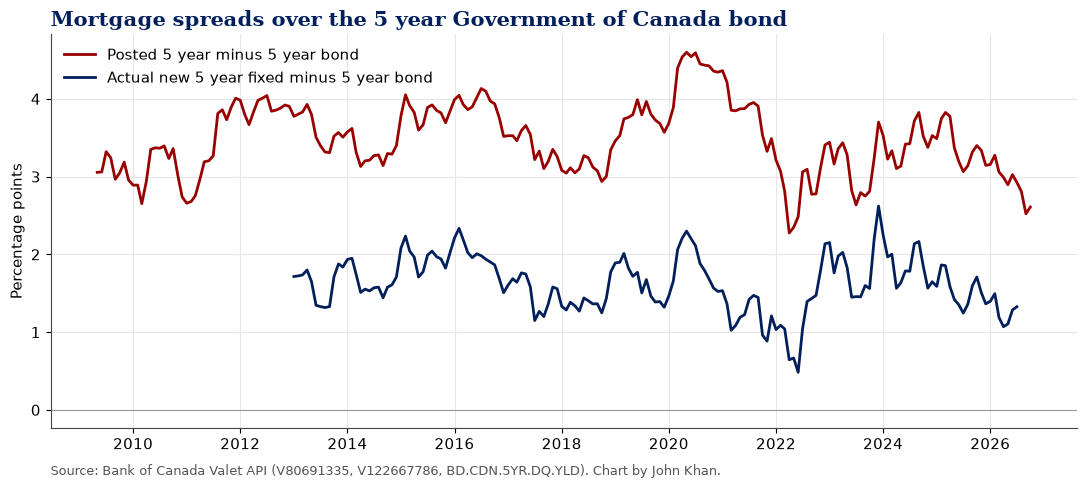

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(m.index, m["posted_spread"], color=RED, lw=2, label="Posted 5 year minus 5 year bond")
ax.plot(m.index, m["effective_spread"], color=BLUE, lw=2, label="Actual new 5 year fixed minus 5 year bond")
ax.axhline(0, color="#999999", lw=0.8)
style(ax, "Mortgage spreads over the 5 year Government of Canada bond", "Percentage points")
ax.legend(loc="upper left")
ax.text(0, -0.12, "Source: Bank of Canada Valet API (V80691335, V122667786, BD.CDN.5YR.DQ.YLD). Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "03_spreads.png")

## 5. The numbers behind the conclusion

In [10]:
last_eff = m["effective5"].last_valid_index()
last_m = m.index.max()
latest = daily.dropna().iloc[-1]
latest_posted = posted.dropna().iloc[-1]
eff = m.dropna(subset=["effective_spread"])
print(f"Latest daily data: {daily.dropna().index[-1].date()}  policy {latest['policy']:.2f}%  5y bond {latest['bond5']:.2f}%")
print(f"Latest posted 5 year rate: {posted.dropna().index[-1].date()}  {latest_posted['posted5']:.2f}%")
print(f"Latest actual new uninsured 5y fixed: {last_eff.strftime('%B %Y')}  {m.loc[last_eff, 'effective5']:.2f}%")
print(f"Posted spread over bond, latest month ({last_m.strftime('%B %Y')}): {m['posted_spread'].iloc[-1]:.2f} pts; average since 2009: {m['posted_spread'].mean():.2f} pts")
print(f"Actual spread over bond, {last_eff.strftime('%B %Y')}: {m.loc[last_eff, 'effective_spread']:.2f} pts; average since {eff.index.min().strftime('%B %Y')}: {eff['effective_spread'].mean():.2f} pts")
print(f"Average discount, posted minus actual: {m['posted_minus_effective'].mean():.2f} pts; {last_eff.strftime('%B %Y')}: {m.loc[last_eff, 'posted_minus_effective']:.2f} pts")
print("Widest posted spread:", m["posted_spread"].idxmax().strftime("%B %Y"), round(m["posted_spread"].max(), 2))
print("Narrowest posted spread:", m["posted_spread"].idxmin().strftime("%B %Y"), round(m["posted_spread"].min(), 2))
print("Widest actual spread:", eff["effective_spread"].idxmax().strftime("%B %Y"), round(eff["effective_spread"].max(), 2))
print("Narrowest actual spread:", eff["effective_spread"].idxmin().strftime("%B %Y"), round(eff["effective_spread"].min(), 2))

Latest daily data: 2026-10-15  policy 2.25%  5y bond 3.53%
Latest posted 5 year rate: 2026-10-14  6.19%
Latest actual new uninsured 5y fixed: July 2026  4.49%
Posted spread over bond, latest month (October 2026): 2.61 pts; average since 2009: 3.47 pts
Actual spread over bond, July 2026: 1.33 pts; average since January 2013: 1.62 pts
Average discount, posted minus actual: 1.89 pts; July 2026: 1.60 pts
Widest posted spread: May 2020 4.6
Narrowest posted spread: April 2022 2.28
Widest actual spread: December 2023 2.62
Narrowest actual spread: June 2022 0.48


## 6. Conclusion

*Figures below are from the run on October 18, 2026, with daily data through October 15, 2026 and actual lending rates through July 2026.*

**1. The bond market explains more of the five year fixed rate than the Bank of Canada does, but it shows up with a delay.** On month to month changes, the five year bond yield alone (this month plus the two before) explains 39% of the movement in the rate borrowers actually got on new uninsured five year fixed loans. The policy rate alone explains 33%. Together they explain 50%. For the posted rate the gap is wider: 25% for the bond against 9% for the policy rate. The strongest bond link comes one to two months later (correlation 0.48 and 0.51), which fits how rate holds work.

**2. Right now is a clean example.** The policy rate has sat at 2.25% since October 30, 2025. Over the same stretch the five year bond went from a monthly average low of 2.75% in November 2025 to 3.58% in October 2026. The actual new five year fixed rate rose from 4.17% in April 2026 to 4.49% in July 2026, and the posted rate moved from 6.09% to 6.19%. Nothing changed at the Bank of Canada, and five year mortgages still got more expensive.

**3. The posted rate is a poor guide to what people pay.** Since 2013 the posted five year rate has averaged 1.89 points above the actual rate on new uninsured five year fixed loans. In July 2026 the gap was 1.60 points (6.09% posted against 4.49% actual).

**4. Banks price five year fixed loans at about 1.6 points over the bond.** The actual rate averaged 1.62 points above the five year bond since 2013. It was 1.33 points in July 2026, below that average. The spread ranged from 0.48 points (June 2022, when bond yields jumped faster than loan rates) to 2.62 points (December 2023, when bond yields fell faster than loan rates).

**What this means for a borrower.** If you are shopping for a five year fixed rate, watch the five year Government of Canada bond, not the next rate announcement. A sustained move in the bond tends to reach lender rate sheets within one to two months.


## Notes and limits

* The posted rate is the chartered bank list rate. Few borrowers pay it, but lenders still use it in some prepayment penalty math, so the gap matters.
* `V122667786` covers new uninsured fixed loans of five years and over at chartered banks only. Credit unions and other lenders are not in it, and insured loans (`V122667780`) price lower.
* Correlation of monthly changes is a simple test. It shows co-movement, not cause.
* Every number above is printed by the code from the data pulled on the run date. If you rerun it later, the latest values will update.

*Data: Bank of Canada, Valet API, https://www.bankofcanada.ca/valet/docs. Used under the Bank of Canada terms of use, https://www.bankofcanada.ca/terms/.*